In [1]:
using Pkg
Pkg.activate("./..")

using CairoMakie
using SURD
using OrdinaryDiffEq

  Activating project at `~/Desktop/github/SURD.jl`


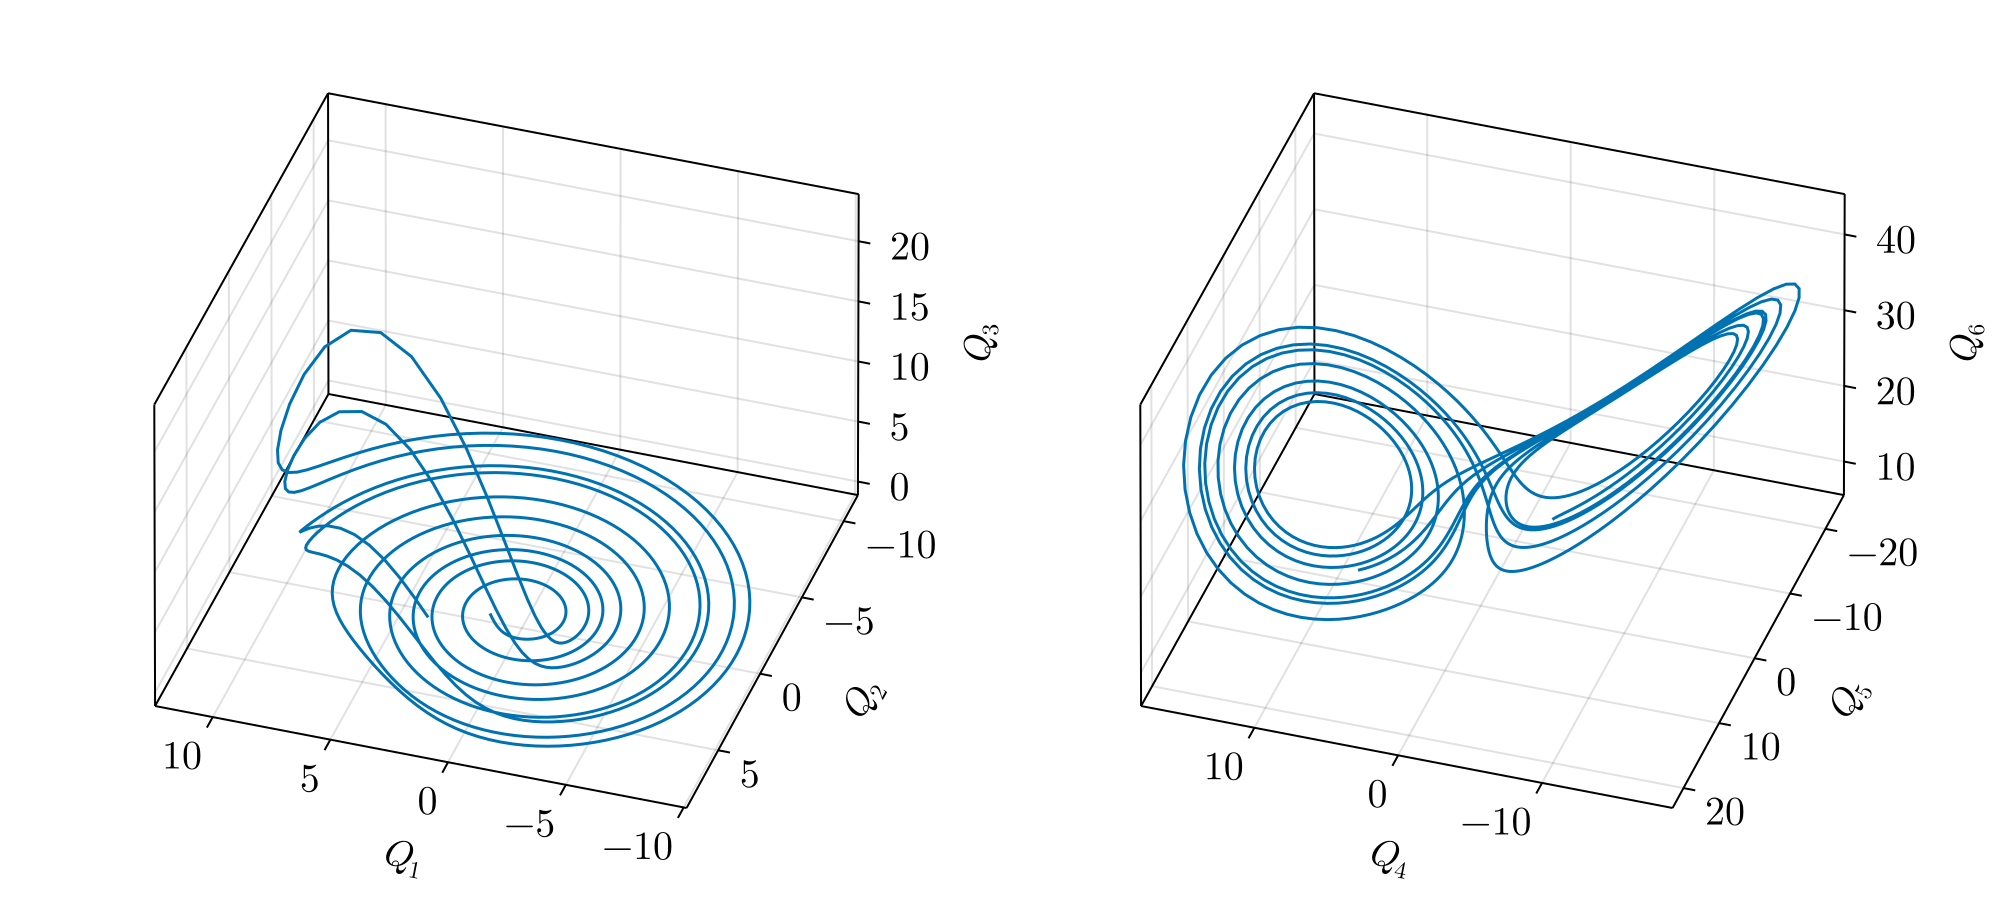

In [37]:
function lorenz_chaos(N, dt)
    q1 = zeros(N)
    q2 = zeros(N)
    q3 = zeros(N)
    q4 = zeros(N)
    q5 = zeros(N)
    q6 = zeros(N)

    c = 0.0

    function lorenz!(du, u, p, t)
        du[1] = - 6.0 * (u[2] + u[3])
        du[2] = 6.0 * (u[1] + 0.2 * u[2])
        du[3] = 6.0 * (0.2 + u[3] * (u[1] - 5.7))
        du[4] = 10.0 * (u[5] - u[4])
        du[5] = u[4] * (28.0 - u[6]) - u[5] + c * u[2]^2
        du[6] = u[4] * u[5] - 8.0 * u[6] / 3.0
    end

    t_save = range(0, step=dt, length=N)
    tspan = (first(t_save), last(t_save))

    prob = ODEProblem(lorenz!, [1.0, 1.0, 1.0, -4.0, -4.0, 15.0], tspan , dt)
    sol = solve(prob, Vern9(), reltol=1e-11, abstol=1e-12, saveat=t_save)
    A = Array(sol)

    q1 = A[1, :]
    q2 = A[2, :]
    q3 = A[3, :]
    q4 = A[4, :]
    q5 = A[5, :]
    q6 = A[6, :]

    return q1, q2, q3, q4, q5, q6
end

Nt = 10_000
dt = 0.01
q1, q2, q3, q4, q5, q6 = lorenz_chaos(Nt, dt)

with_theme(theme_latexfonts(), fontsize=20) do
    fig = Figure(size=(1000, 450))
    ax = Axis3(fig[1, 1], azimuth=0.6π, elevation=0.2π, xlabel=L"Q_1", ylabel=L"Q_2", zlabel=L"Q_3")
    lines!(ax, q1[1:(end÷10)], q2[1:(end÷10)], q3[1:(end÷10)])

    ax2 = Axis3(fig[1, 2], azimuth=0.6π, elevation=0.2π, xlabel=L"Q_4", ylabel=L"Q_5", zlabel=L"Q_6")
    lines!(ax2, q4[1:(end÷10)], q5[1:(end÷10)], q6[1:(end÷10)])
    fig
end

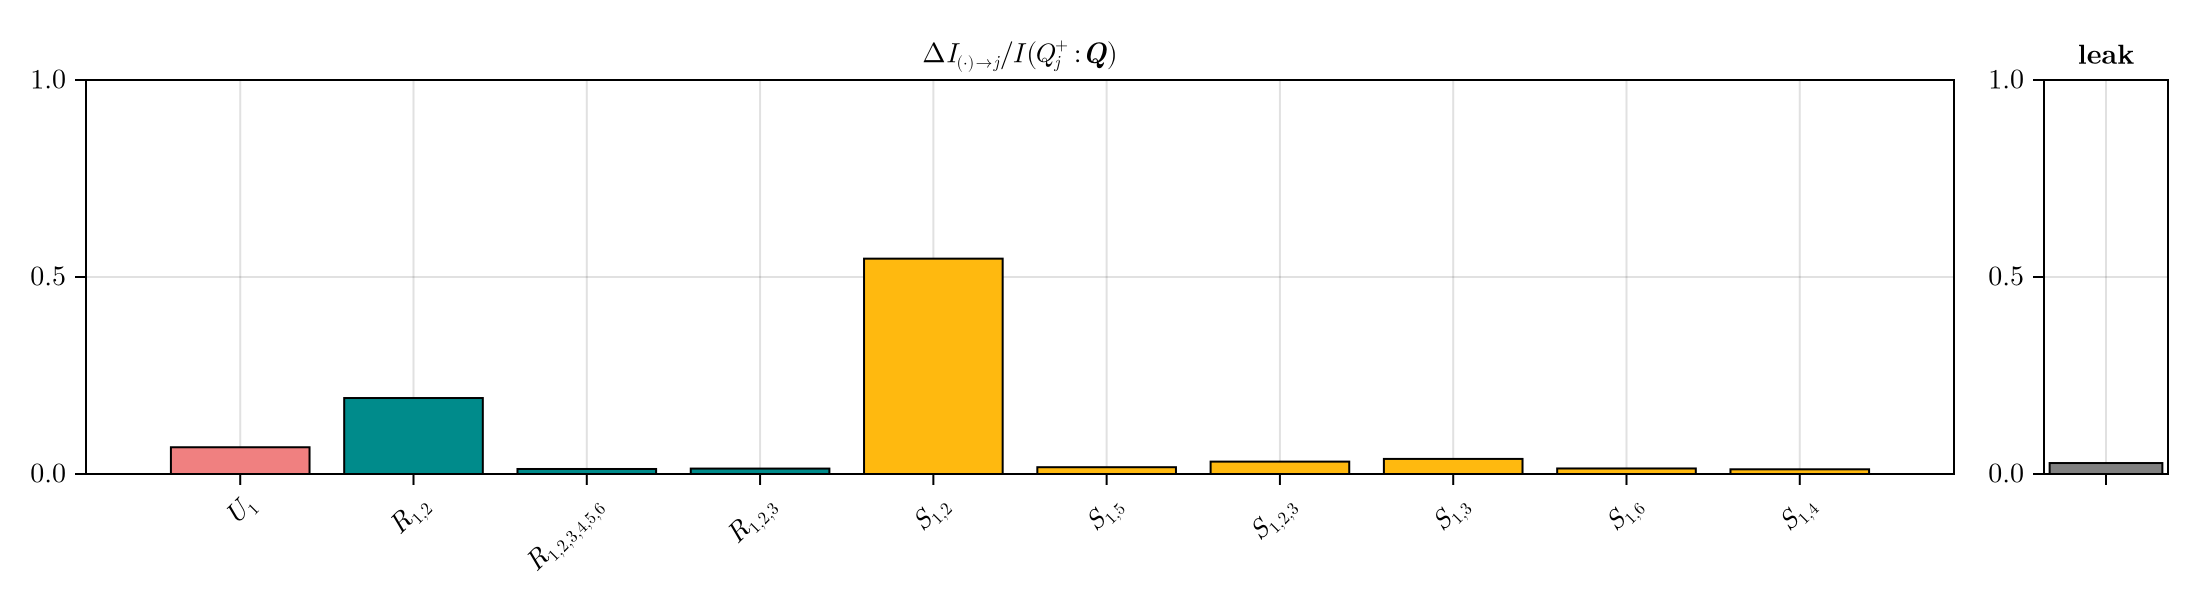

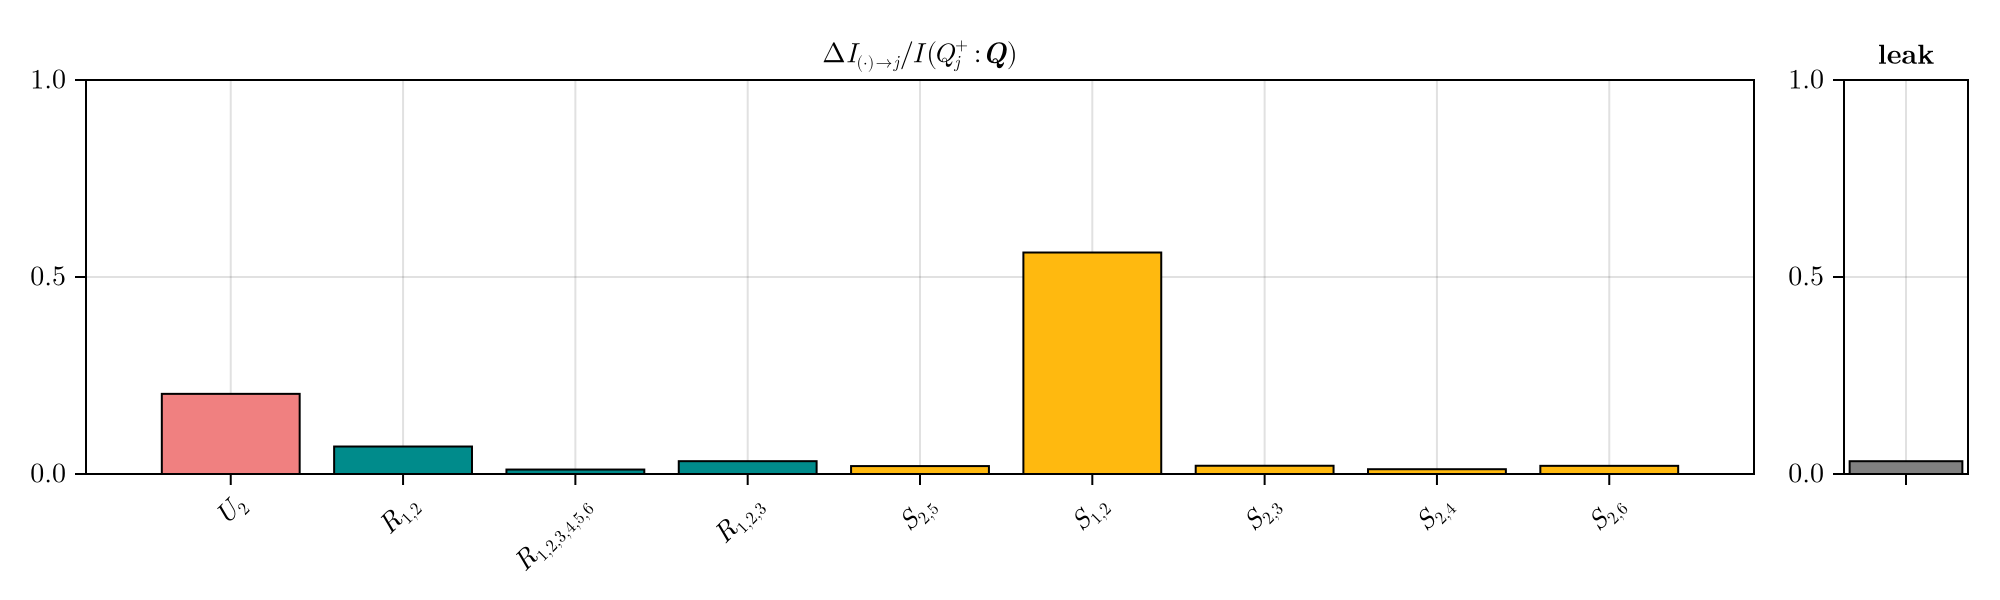

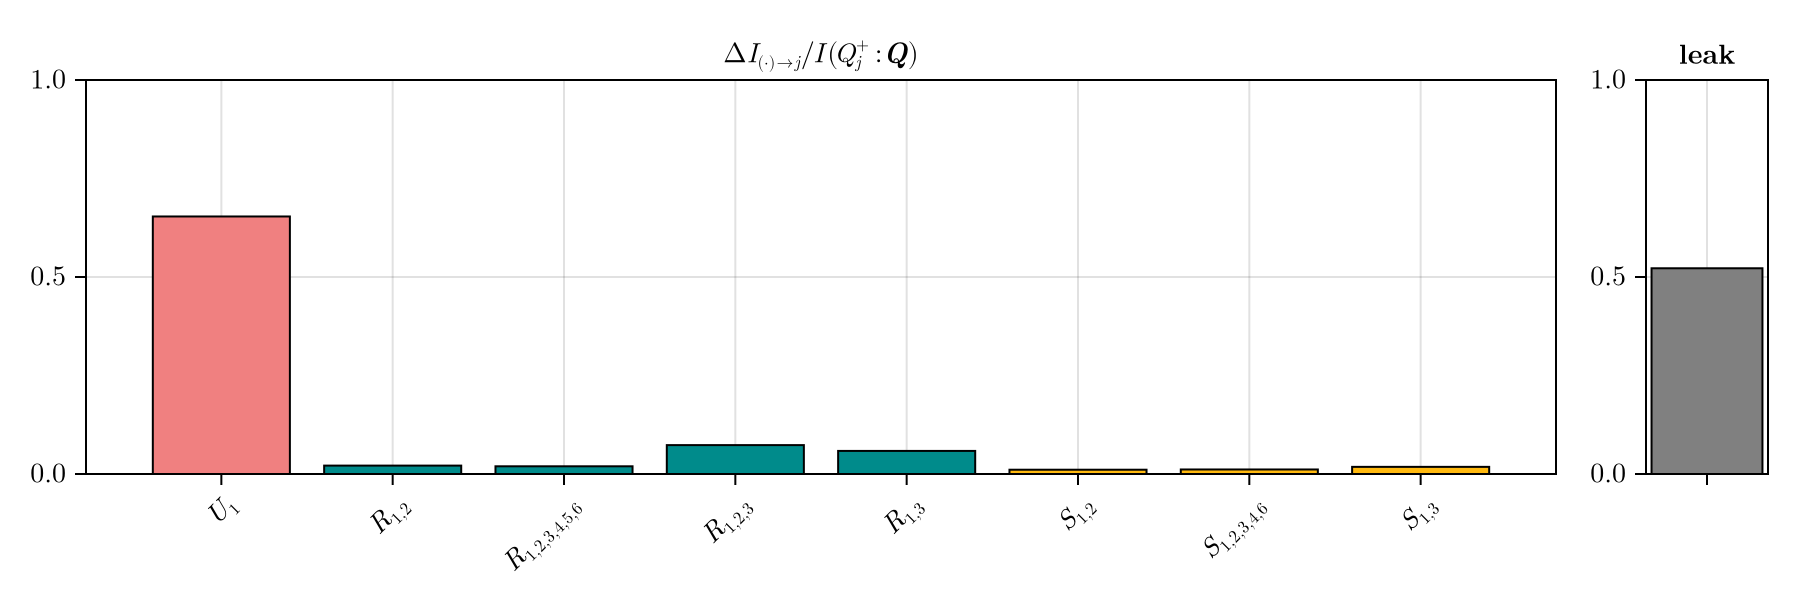

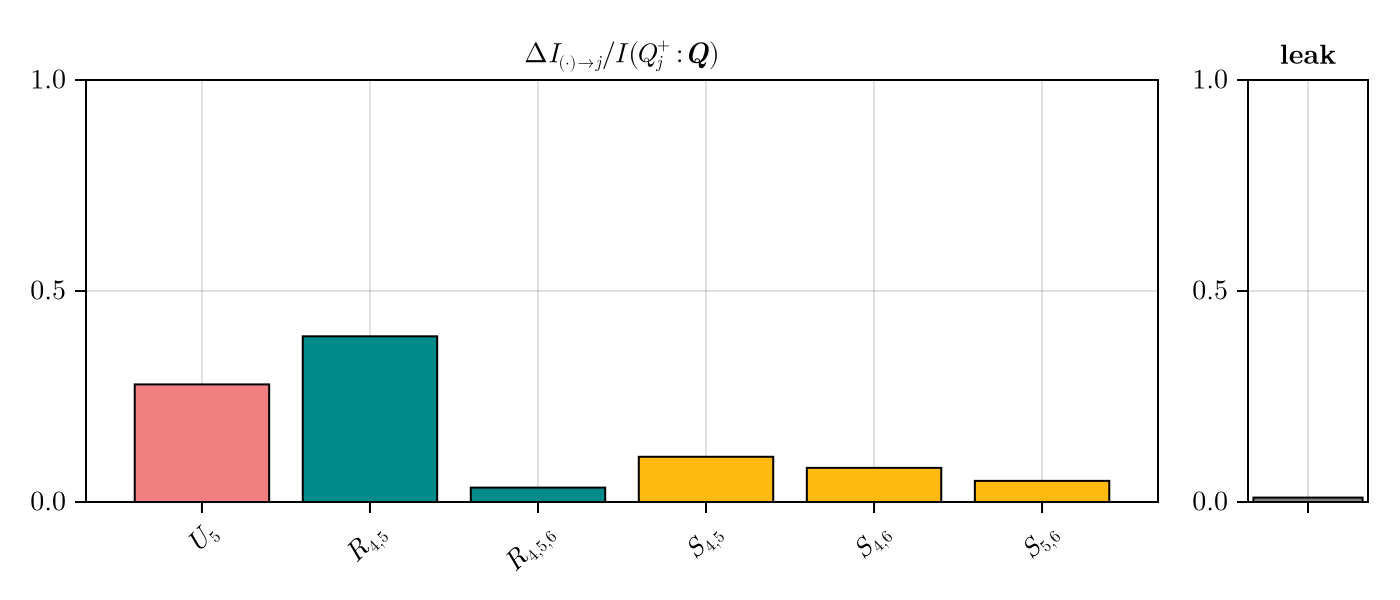

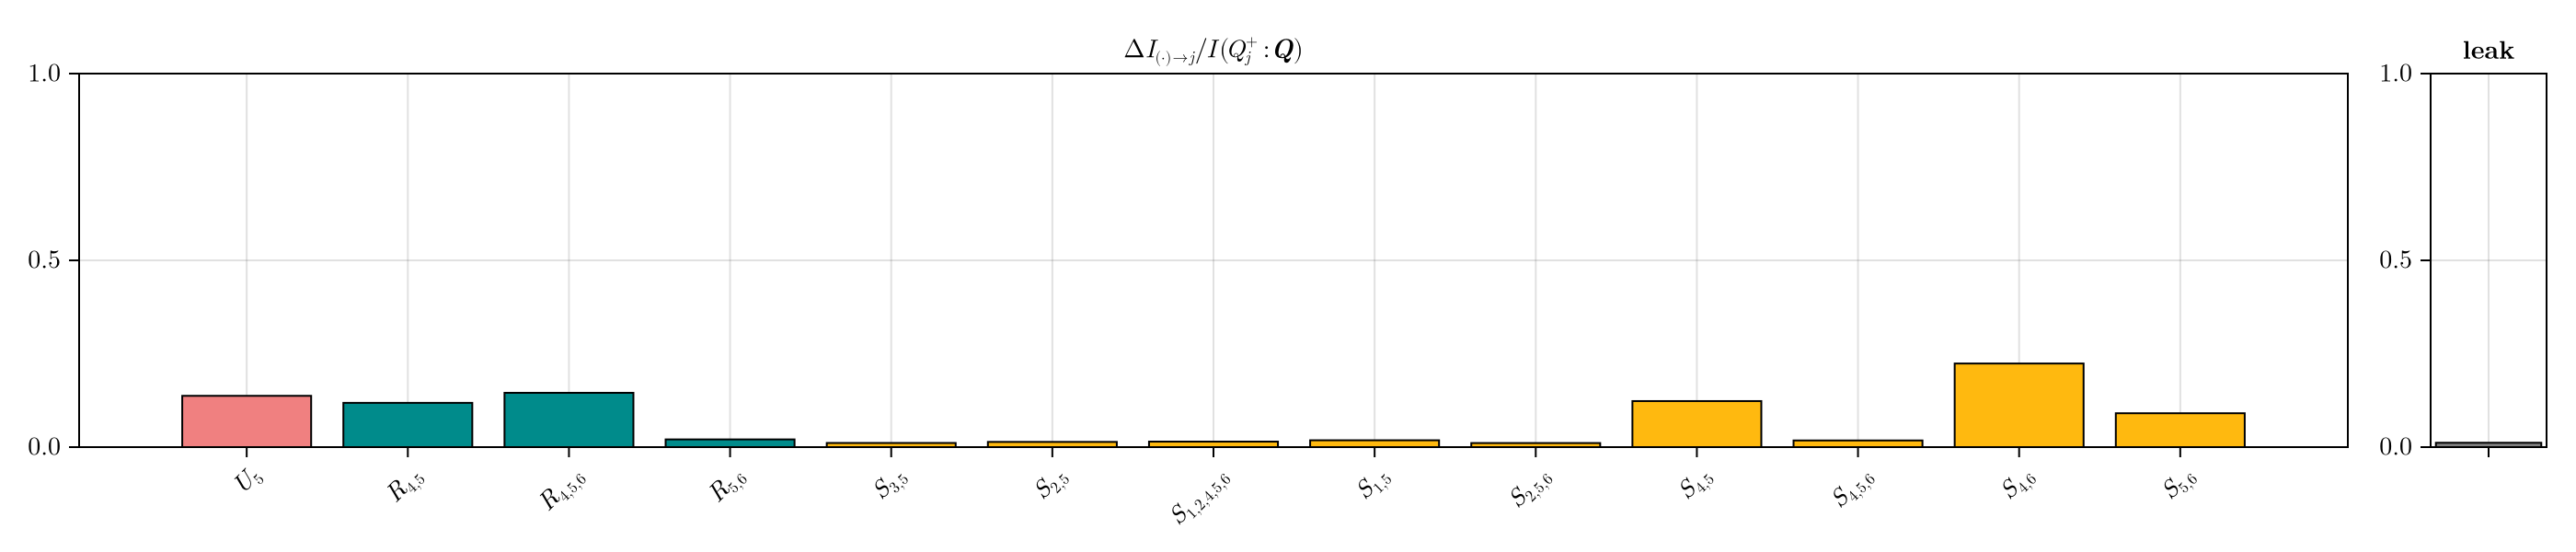

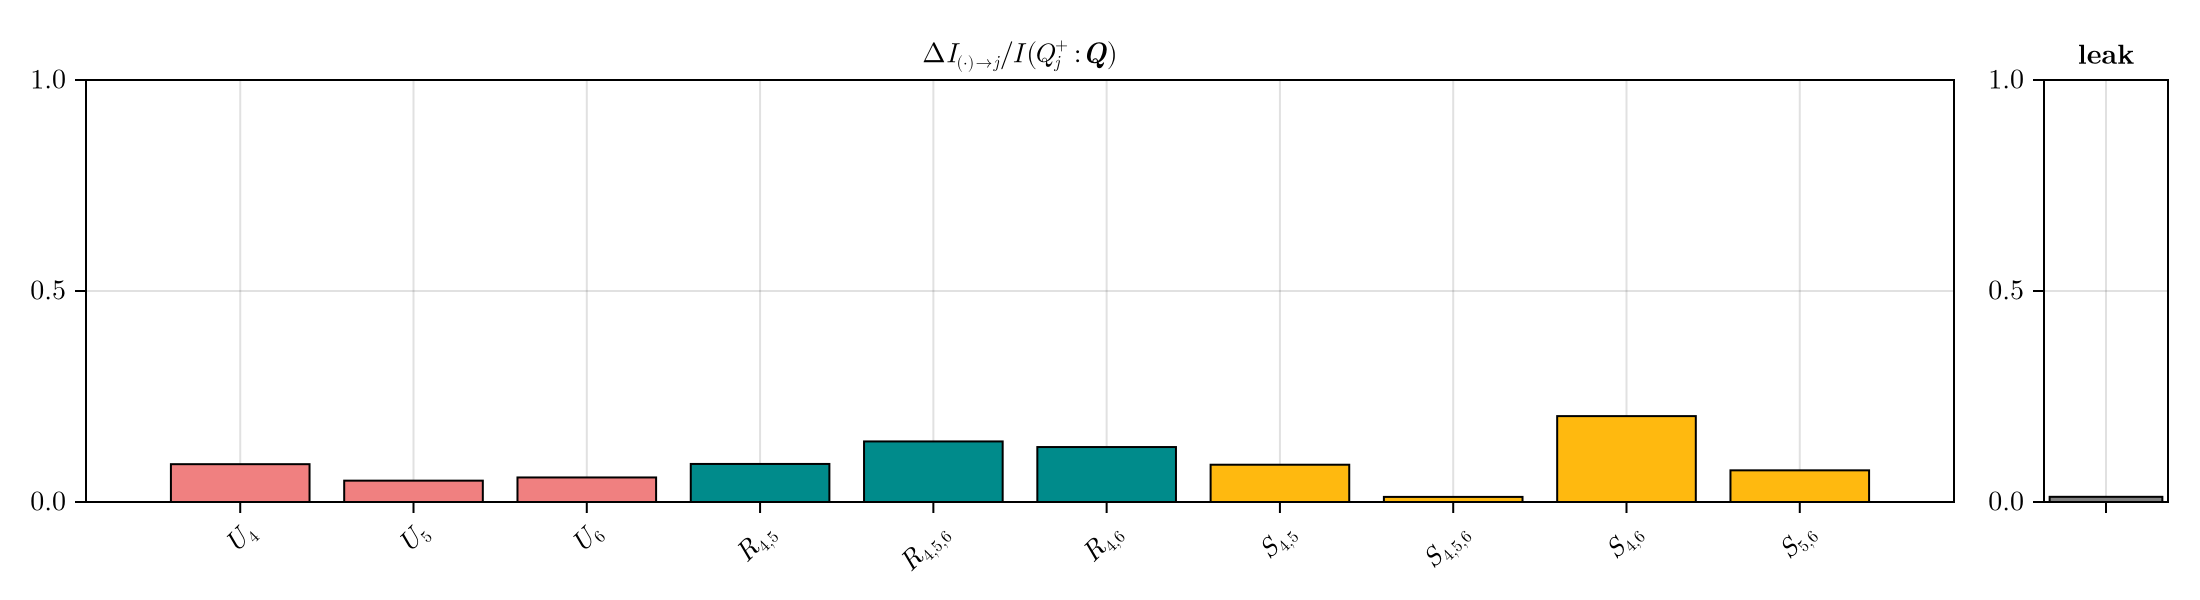

CairoMakie.Screen{IMAGE}


In [38]:
lag = 10
result1 = surd(q1[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
result2 = surd(q2[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
result3 = surd(q3[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
result4 = surd(q4[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
result5 = surd(q5[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
result6 = surd(q6[1+lag:end], (q1[1:end-lag], q2[1:end-lag], q3[1:end-lag], q4[1:end-lag], q5[1:end-lag], q6[1:end-lag]), SURD.kNN())
display(surd_plot(result1))
display(surd_plot(result2))
display(surd_plot(result3))
display(surd_plot(result4))
display(surd_plot(result5))
display(surd_plot(result6))